### BowyerWatson Algorithm

In [35]:
import matplotlib.pyplot as plt
from matplotlib.patches import Polygon
import math
import random

In [36]:
class Point:
    x = None
    y = None

    def __init__(self,coor_x,coor_y):
        self.x=coor_x
        self.y=coor_y

    def __lt__(self, other):
      if(self.x != other.x):
        return self.x < other.x
      return self.y < other.y
    
    def plot(self, tag='', color=''): 
        kwargs = {} # A modification of the original class, allows passing independent arguments
        if color:
            kwargs['c'] = color
        if tag:
            kwargs['label'] = tag

        plt.scatter(self.x, self.y, **kwargs)
            
        if tag:
            plt.legend()
            
    def __repr__(self):
      return f"({self.x:.2f}, {self.y:.2f})"

In [ ]:
class Segment:
    start = None
    end = None
    angle = None
    half = None

    def __init__(self, A, B ):
        if A < B:
            self.start = A
            self.end = B
        else:
            self.start = B
            self.end = A
    
        self.angle = self.calcAngle()
        self.half  = self.calcHalf()

    def __eq__(self,other): ## Compare segments and check if they are the same, even if they are in different order
        return (self.start == other.end and self.end == other.start) or (self.start == other.start and self.end == other.end)
        
    def __repr__(self): 
      return f"[{self.start}, {self.end}]"

    def plot(self, tag='', color=''):
        kwargs = {} 
        if color:
            kwargs['c'] = color
        if tag:
            kwargs['label'] = tag

        segmento = [ [self.start.x, self.start.y ],  [self.end.x, self.end.y ] ]

        self.start.plot(**kwargs)
        self.end.plot(**kwargs)
        if color:
            plt.plot( [s[0] for s in segmento], [s[1] for s in segmento] ,  linestyle="-", color =color)
        else:
            plt.plot( [s[0] for s in segmento], [s[1] for s in segmento] ,  linestyle="-")

    def calcHalf(self):
        x = None
        y = None
        if(self.start.x == self.end.x): ## When the points are in the same x-axxis
            x = self.start.x
        else: 
            x = self.start.x + abs(self.start.x-self.end.x)/2

        if(self.start.y == self.end.y): # Both on the same y axxis
            y = self.start.y
        else:
            y = min(self.end.y,self.start.y) + abs(self.start.y-self.end.y)/2 

        
        #print(f"start: {self.start}, end: {self.end}, half: ({x},{y})")
        return Point(x, y)


    def calcAngle(self):
        if(self.start.y == self.end.y): #Division by 0
            return 0
        if(self.start.x == self.end.x): # 90 degrees
            return float('inf')

        M = (self.start.x-self.end.x) / (self.start.y-self.end.y)
        return 
        


In [38]:
class Triangle:
    circumcenter = None
    circumradius = None
    triangle = None
    circumcircle = None

    def __init__(self,p1, p2,p3):

        self.points = []
        self.segments = []

        self.points.append(p1)
        self.points.append(p2)
        self.points.append(p3)

        self.segments.append(Segment(p1,p2))
        self.segments.append(Segment(p2,p3))
        self.segments.append(Segment(p3,p1))

        self.circumcenter, self.circumradius = self.calculateCircumcenter()
        self.triangle = Polygon([(p.x,p.y) for p in self.points], closed=True, facecolor='lightblue', edgecolor='darkgreen', alpha=0.2)
        if self.circumcenter is not None and self.circumradius is not None:
            self.circumcircle = plt.Circle((self.circumcenter.x, self.circumcenter.y), self.circumradius, color='lightblue', fill=False, linestyle='-', linewidth=1)
        else:
            self.circumcircle =  plt.Circle((0,0), 0.00000001, color='lightblue', fill=False, linestyle='-', linewidth=1)  # Circumcircle is undefined for collinear points
    def __repr__(self):
          return f"[{self.points[0]}, {self.points[1]},{self.points[2]}]"
    
    def plot(self,ax):
        for p in self.points:
            p.plot()

        #self.circumcenter.plot(tag='Circumcenter', color='red') 
            
        ax.add_patch(self.triangle)
        #ax.add_patch(self.circumcircle)

    def calculateCircumcenter(self):
        A = self.points[0]
        B = self.points[1]
        C = self.points[2]

        D = 2 * (A.x * (B.y - C.y) + B.x * (C.y - A.y) + C.x * (A.y - B.y))
        if D == 0:
            return None, None  # The points are collinear, circumcenter is undefined

        Ux = ((A.x**2 + A.y**2) * (B.y - C.y) + (B.x**2 + B.y**2) * (C.y - A.y) + (C.x**2 + C.y**2) * (A.y - B.y)) / D
        Uy = ((A.x**2 + A.y**2) * (C.x - B.x) + (B.x**2 + B.y**2) * (A.x - C.x) + (C.x**2 + C.y**2) * (B.x - A.x)) / D
        
        radio = math.sqrt((Ux - A.x)**2 + (Uy - A.y)**2)

        return Point(Ux, Uy), radio
    

In [39]:
def calculateSuperTriangle(points):
    y_min = float('inf')
    y_max = float('-inf')
    x_min = float('inf')
    x_max = float('-inf')

    for p in points:
        y_min = min(p.y, y_min)
        y_max = max(p.y, y_max)
        x_min = min(p.x, x_min)
        x_max = max(p.x, x_max)

    x_len = abs(x_max - x_min)
    y_len = abs(y_max - y_min)

    if y_min == y_max or x_min == x_max or len(points) == 0:
        print("La figura forma una línea o está vacía")
        return

    # We draw a square using this maxes
    upper_left = Point(x_min, y_max)
    upper_right = Point(x_max, y_max)
    lower_right = Point(x_max, y_min)
    lower_left = Point(x_min, y_min)

    # We create a triangle, the upper point is in the middle of the upper edge of the rectangle, plus the 
    middle_point = Point(x_min+(x_max-x_min)/2, y_max+(y_len+x_len)/2)
    # f(x) = mx+b  -> y = mx+b
    m = (upper_left.y-middle_point.y)/(upper_left.x-middle_point.x)

    # b = y -mx
    b1 = upper_left.y - m * upper_left.x
    b2 = upper_right.y - (-m) * upper_right.x

    # x = (y-b)/m
    left_point = Point((y_min-b1)/m, y_min)
    right_point = Point((y_min-b2)/(-m), y_min)

    #middle_point.plot()
    #left_point.plot()
    #right_point.plot()
#
    #plt.axhline(y=y_min, color='b', linestyle='--', label='ymin')
    #plt.axhline(y=y_max, color='b', linestyle='--', label='ymax')
    #plt.axvline(x=x_min, color='b', linestyle='--', label='xmin')
    #plt.axvline(x=x_max, color='b', linestyle='--', label='xmax')
#
    #plt.axvline(x=x_min+(x_max-x_min)/2, color='b', linestyle='--', label='xmax')

    triangle_points = [left_point,middle_point,right_point]
    triangle_coords=[(p.x,p.y) for p in triangle_points]
    triangle = Polygon(triangle_coords, closed=True, facecolor='lightgreen', edgecolor='darkgreen', alpha=0.3)

    rectangle_points = [upper_left, upper_right , lower_right, lower_left]
    rectangle_coords = [(p.x,p.y) for p in rectangle_points]
    rectangle = Polygon(rectangle_coords, closed=True, facecolor='lightblue', edgecolor='darkgreen', alpha=0.6)


    #ax.add_patch(triangle)
    #ax.add_patch(rectangle)

    #for p in points:
    #    p.plot()

    return triangle_points



In [40]:
def bowyerWatson(points):
    bigTriangle = calculateSuperTriangle(points)
    T = []
    T.append(Triangle(bigTriangle[0],bigTriangle[1],bigTriangle[2]))

    for p in points:
        print("Point",p)
        badTriangles = [t for t in T if t.circumcircle.contains_point((p.x,p.y))]
        print("badTriangles:",badTriangles)
        uniqueEdges = []
        for i in range(len(badTriangles)):

            for segment1 in badTriangles[i].segments:
                unique = True
                for j in range(len(badTriangles)):
                    if i==j:
                        continue

                    for segment2 in badTriangles[j].segments:
                        if segment1 == segment2:
                            unique = False

                if unique: 
                    uniqueEdges.append(segment1)
            
        print("Unique edges:",uniqueEdges)
        tempT = []
        for t in T:
            if not(t in badTriangles): # Double for to avoid editing a list while iterating over it
                tempT.append(t)
            else:
                print('-'*10,"Removed",'-'*10)

        T = tempT

        for edge in uniqueEdges:
            newT = Triangle(p,edge.start,edge.end)
            T.append(newT)
        print("T:",T)


    print("BigTriangle:",bigTriangle)
    tempT = []

    for t in T:
        if not(bigTriangle[0] in t.points or bigTriangle[1] in t.points or bigTriangle[2] in t.points):
            print('-'*10,"Removed",'-'*10)
            tempT.append(t)
    T=tempT

    print("Final T:",T)
    return T        



Passed


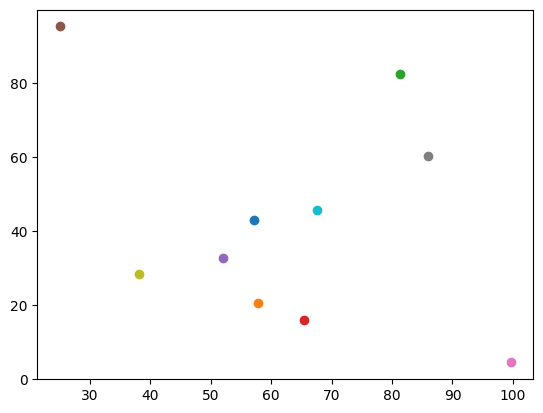

Point (57.14, 42.89)
badTriangles: [[(-15.98, 4.46), (62.33, 178.02),(140.63, 4.46)]]
Unique edges: [[(-15.98, 4.46), (62.33, 178.02)], [(62.33, 178.02), (140.63, 4.46)], [(-15.98, 4.46), (140.63, 4.46)]]
---------- Removed ----------
T: [[(57.14, 42.89), (-15.98, 4.46),(62.33, 178.02)], [(57.14, 42.89), (62.33, 178.02),(140.63, 4.46)], [(57.14, 42.89), (-15.98, 4.46),(140.63, 4.46)]]
Point (57.81, 20.61)
badTriangles: [[(57.14, 42.89), (-15.98, 4.46),(140.63, 4.46)]]
Unique edges: [[(-15.98, 4.46), (57.14, 42.89)], [(-15.98, 4.46), (140.63, 4.46)], [(57.14, 42.89), (140.63, 4.46)]]
---------- Removed ----------
T: [[(57.14, 42.89), (-15.98, 4.46),(62.33, 178.02)], [(57.14, 42.89), (62.33, 178.02),(140.63, 4.46)], [(57.81, 20.61), (-15.98, 4.46),(57.14, 42.89)], [(57.81, 20.61), (-15.98, 4.46),(140.63, 4.46)], [(57.81, 20.61), (57.14, 42.89),(140.63, 4.46)]]
Point (81.33, 82.36)
badTriangles: [[(57.14, 42.89), (62.33, 178.02),(140.63, 4.46)]]
Unique edges: [[(57.14, 42.89), (62.33, 178

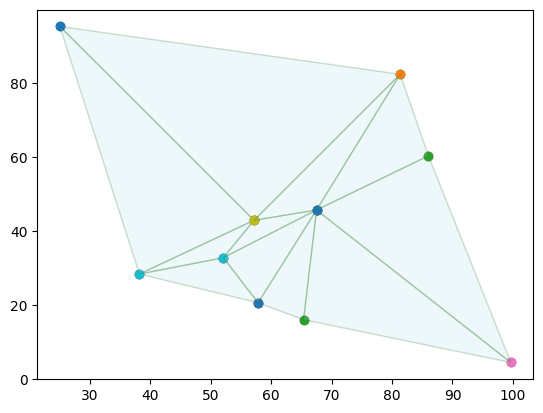

In [41]:

random.seed(10)
coordinates_large = [
    [random.uniform(0, 100), random.uniform(0, 100)]
    for _ in range(10)
]
points_large = [Point(x, y) for x, y in coordinates_large]

print("Passed")

for p in points_large:
    p.plot()
plt.show()

delaunay_triangulation = bowyerWatson(points_large)
fig, ax = plt.subplots()
print("Plotting")
for t in delaunay_triangulation:
    t.plot(ax)